# Best GH

- Input parameters
  - Number of groups
  - Name ref variable
  - Name perf variable
 

- Options
  - Tree/graph search problem approach
     - Data structures:
         - Set of visited states
         - Priority queue sorted by minimum fitness function value
         - Attribute to keep the current best visited state
     
     - Initialization:
         - Based on the provided number of groups, obtain n-tiles per ref
         - Obtain mean perf value for each tile for each ref
         - Caclculate the mean perf std deviation of each tile across the refs
         - Fitness function: sum of tiles std. devs

     - Iteration:
         - Select the tile with the largest mean perf variance
         - Generate 2 new states:
           - Observation with highest positive std deviation within the tile*  is assigned to upper tile
           - Observation with lowest (highest negative) std deviation within the tile* is assigned to lower tile
         - Calculate fitness function for each new state
         - Check if new states yield better (lower) fitness function value than current 
         - Add both new states to a priroty queue based on their fitness function value
         - Add current state to visited states set
         - Advance to the (already prioritized) next state on queue

    *obtained by averaging the std dev of each obs across the tiles



  - Linear optimization problem approach
    - Minimize sum of tile's std_dev(X:bad) subject to a reasonable ordination(Y:score) across refs and tiles

# Auto GH

In [1]:
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt


def plot_gh(df, ref, perf, gh, perf_denominator=None):
    #Plot GH distribution and performance over time.
    # Initiate subplots
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    # calculate percentage of GH by ref 
    df_count = df.groupby([ref, gh], as_index=False).apply( lambda x: pd.Series({"percentage": len(x)}))
    
    df_count["percentage"] = df_count["percentage"] / df_count.groupby(ref)[
        "percentage"
    ].transform(sum)
    
    # Plots GH distribution over time 
    df_count.pivot_table("percentage", ref, gh).plot( 
        kind="bar", stacked=True, ax=ax[0])
    ax[0].legend(loc="lower left")
    ax[0].set_title("GH distribution over time")
    
    # Calculate mean perf by ref and GH
    if perf_denominator is None:
        df_perf = df.groupby([ref, gh], as_index=False) [perf].mean()
    else:
        df_perf = df.groupby([ref, gh], as_index=False) [perf].sum()
        df_perf[perf] = ( df_perf[perf] /df.groupby([ref, gh]) [perf_denominator].sum().values)
        
    # Plots performance over time
    df_perf[ref] = df_perf[ref].astype(str)
    df_perf.pivot_table(perf, ref, gh).plot(ax=ax[1])
    ax[1].legend(loc="lower left")
    ax[1].set_title("Performance over time")

    # Calculate Log odds by ref and GH
    df_odds = (
        df.groupby([ref, gh]) .apply(lambda x: np.log( x[x[perf] > 0].shape[0] / x[~(x[perf] > 0)].shape[0]
    )).reset_index() .rename(columns={0: "log_odds"}))
    # Plots performance over time
    df_odds[ref] = df_odds[ref].astype(str) 
    df_odds.pivot_table("log_odds", ref, gh).plot(ax=ax[2])
    ax[2].legend(loc="lower left")
    ax[2].set_title("Log odds over time")
    # Rotate x labels
    for axis in ax: axis.tick_params(axis="x", labelrotation=90)
                                                           

In [2]:
def check_gh(
    df,
    ref,
    perf,
    gh,
    gh_min_size=0.05,
    z_min=2,
    perf_denominator=None
):
    # Calculate percentage of GH by ref 
    df_count = df.groupby(by=[ref, gh])[[ref, gh]].apply( lambda x: pd.Series({"percentage": len(x)}))
    df_count["percentage"] = df_count["percentage"] / df_count.groupby(ref)["percentage"].transform('sum')
    # print(df_count)
    df_count.reset_index(inplace=True)
    
    # Calculate mean perf by ref and GH
    if perf_denominator is None: 
        df_perf = df.groupby([ref, gh])[perf].mean()
        df_perf = df_perf.reset_index()
        df_perf.columns = list(df_perf.columns)[:-1] + ['PERF']
    else: 
        df_perf = df.groupby([ref, gh])[perf].mean()
        df_perf = df_perf.reset_index()
        df_perf.columns = list(df_perf.columns)[:-1] + ['PERF']
        df_perf[perf] = (df_perf[perf]/df.groupby([ref, gh])[perf_denominator].sum().values)

    # Generate the check report by GH and calculating 
    report = df_count.groupby(gh, as_index=False)[
        "percentage"
    ].mean() # Mean percentage by GH
    
    # Mean perf by GH
    report["mean_perf"] = df_perf.groupby(gh)[perf].mean().values
    #Std dev of perf by GH
    report["std_perf"] = df_perf.groupby(gh)[perf].std().values
    # Mean perf of previous GH
    report["mean_prev"] = report["mean_perf"].shift(1)
    # Std dev of perf of previous GH
    report["std_prev"] = report["std_perf"].shift(1)
    
    # Calculate z-score
    report["z"] = (report["mean_perf"] - report["mean_prev"]) / ((report["std_perf"] ** 2 + report["std_prev"] ** 2) ** 0.5)
    #Check column
    report["ok"] = (report["percentage"] > gh_min_size) & ((report["mean_prev"].isna()) | (report["z"] > z_min))
    # Set GH as index
    report = report.set_index(gh)
    return report

In [3]:
def get_cut_points(
    df,
    ref,
    perf,
    score,
    gh_min_size=0.05,
    z_min=2,
    step=0.01,
    perf_denominator=None
):
    # Initial cut points 
    cut_points = [0, 1]
    # Flag that indicates to continue 
    not_end = True
    # Instantiate progress bar 
    pbar = tqdm(total=len(np.arange(step, 1, step)), position=0, leave=True)
    
    while not_end:
        # Set flag to stop if no one new point be found 
        not_end = False
        # Loop thru every step 
        for i in np.arange(cut_points[-2] + step, 1, step):
            # Update progress bar
            pbar.update(1)
            # Insert new point in the end 
            new_cut_points = cut_points[:-1] + [i] + cut_points[-1:]
            # Create GH Labels 
            labels = np.arange(1, len(new_cut_points))
            # Create dataframe with GHS
            gh = pd.DataFrame(
                {"gh": pd.cut(df[score], bins=new_cut_points, labels=labels)}
            )
            
            # Check if all GHS are 'ok' with constraints
            if check_gh(
                pd.concat([df, gh], axis=1),
                ref,
                perf,
                "gh",
                gh_min_size,
                z_min,
                perf_denominator,
            )["ok"].all():
                # Update cut points
                cut_points = new_cut_points
                # Set flat to continue looking for new cut points
                not_end = True
                break

    pbar.close()
    return [float(cp) for cp in cut_points] 

In [4]:
def get_gh(df, score, cut_points):
    ghs = pd.cut(
        df[score], 
        bins=cut_points,
        labels=np.arange(1, len(cut_points))
    )
    return ghs

In [5]:
import numpy as np
import pandas as pd
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=DeprecationWarning)
warnings.simplefilter(action='ignore', category=RuntimeWarning)

ref = [2306]*40 + [2307]*40 + [2308]*38
perf = [0]*50 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*2 + [0]*10 + [1]*8
score = [float(scr) for scr in np.linspace(0,1,118)]

In [6]:
np.random.seed(42)
np.random.shuffle(ref)
ref[:10]

[2307, 2308, 2306, 2307, 2306, 2308, 2307, 2306, 2308, 2307]

In [7]:
df = pd.DataFrame({'SAFRA': ref, 'PERF': perf, 'SCORE': score})

In [8]:
df.SAFRA.value_counts()

SAFRA
2307    40
2306    40
2308    38
Name: count, dtype: int64

In [9]:
df.groupby('SAFRA').SCORE.mean()

SAFRA
2306    0.461111
2307    0.491239
2308    0.550157
Name: SCORE, dtype: float64

In [10]:
df.groupby('SAFRA').PERF.mean()

SAFRA
2306    0.150000
2307    0.150000
2308    0.157895
Name: PERF, dtype: float64

In [11]:
df.head()

,SAFRA,PERF,SCORE
0,2307,0,0.000000
1,2308,0,0.008547
2,2306,0,0.017094
3,2307,0,0.025641
4,2306,0,0.034188


In [12]:
df['SAFRA']

0      2307
1      2308
2      2306
3      2307
4      2306
       ... 
113    2308
114    2306
115    2308
116    2307
117    2308
Name: SAFRA, Length: 118, dtype: int64

In [13]:
cp = get_cut_points(df,'SAFRA','PERF','SCORE',z_min=0.5, step=0.01)

100%|██████████| 99/99 [00:00<00:00, 146.62it/s]


In [14]:
cp

[0.0, 0.060000000000000005, 0.4299999999999998, 0.5299999999999999, 0.65, 1.0]

In [15]:
df['GH'] = get_gh(df,'SCORE',cp)
df.GH.fillna(1,inplace=True)

In [16]:
df.GH.value_counts()

GH
2    43
5    41
4    14
3    12
1     8
Name: count, dtype: int64

In [17]:
pd.crosstab(df.GH,df.SAFRA)

SAFRA,2306,2307,2308
GH,,,
1,3,3,2
2,16,16,11
3,5,3,4
4,7,3,4
5,9,15,17


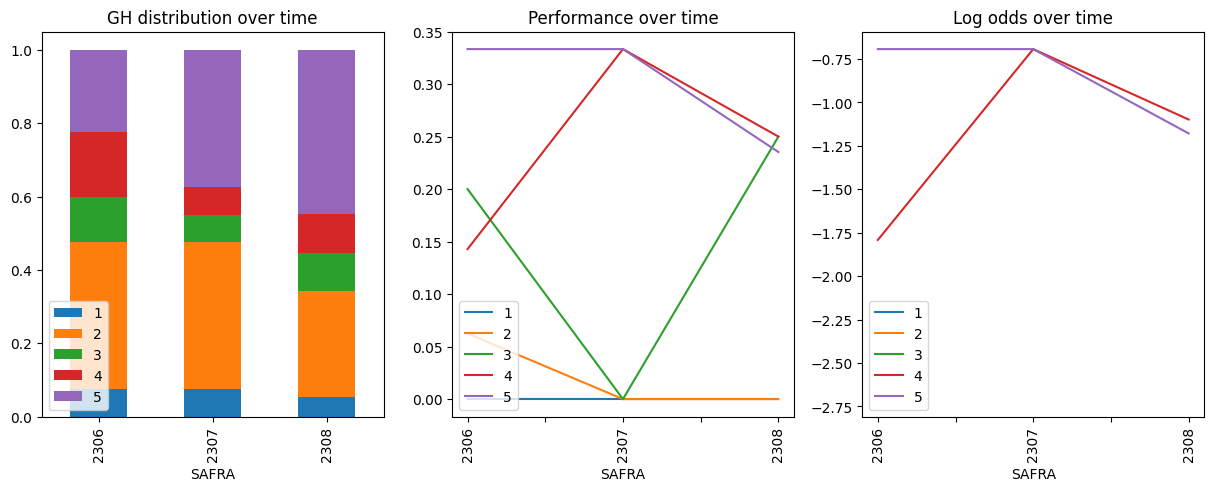

In [18]:
plot_gh(df, 'SAFRA', 'PERF', 'GH')

In [19]:
pd.crosstab(df.GH,df.SAFRA)

SAFRA,2306,2307,2308
GH,,,
1,3,3,2
2,16,16,11
3,5,3,4
4,7,3,4
5,9,15,17


In [20]:
df.groupby(['GH','SAFRA']).PERF.mean().unstack().sort_index(ascending=False)

SAFRA,2306,2307,2308
GH,,,
5,0.333333,0.333333,0.235294
4,0.142857,0.333333,0.250000
3,0.200000,0.000000,0.250000
2,0.062500,0.000000,0.000000
1,0.000000,0.000000,0.000000


In [21]:
df.loc[df.SAFRA==2308]

,SAFRA,PERF,SCORE,GH
1,2308,0,0.008547,1
5,2308,0,0.042735,1
8,2308,0,0.068376,2
11,2308,0,0.094017,2
13,2308,0,0.111111,2
16,2308,0,0.136752,2
18,2308,0,0.153846,2
19,2308,0,0.162393,2
22,2308,0,0.188034,2
28,2308,0,0.239316,2


In [19]:
# pd.DataFrame(np.hstack([df[df.SAFRA==ref].sort_values('SCORE') for ref in np.sort(df['SAFRA'].unique())]), columns=['SAFRA_1','PERF_1','SCORE_1','GH_1', 'SAFRA_2','PERF_2','SCORE_2','GH_2', 'SAFRA_3','PERF_3','SCORE_3','GH_3'])

# Best GH

In [20]:
from pulp import *

In [21]:
safra = 'SAFRA'
perf = 'PERF'
score = 'SCORE'
gh = 'GH'
index = 'INDEX'
n_groups = 4

In [22]:
refs_list = sorted([int(sfr) for sfr in df[safra].unique()])
refs_list

[2306, 2307, 2308]

In [23]:
groups_list = sorted([int(grp) for grp in np.arange(1,n_groups+1)])
groups_list

[1, 2, 3, 4]

In [25]:
#idx_list = [str(i) for i in range(0,np.max([len(df[df[safra]==int(ref)]) for ref in refs_list]))]
idx_list = [[i+1 for i in range(0,len(df[df[safra]==ref]))] for ref in refs_list]
idx_list

[[1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40],
 [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40],
 [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38]]

In [26]:
idx_dict = {ref:[i for i in range(1,len(df[df[safra]==ref]) + 1)] for ref in refs_list}
idx_dict

{2306: [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40],
 2307: [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40],
 2308: [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38]}

In [ ]:
# VI1G1R1 ==> assigning vars

# BADG1R1 => (VI1G1R1*PERF[I1,R1] + VI2G1R1*PERF[I2,R1] + VI3G1R1*PERF[I3,R1] ...) / (VI1G1R1 + VI2G1R1 + VI3G1R1 + ...)
# BADG2R1 => (VI1G2R1*PERF[I1,R1] + VI2G2R1*PERF[I2,R1] + VI3G2R1*PERF[I3,R1] ...) / (VI1G2R1 + VI2G2R1 + VI3G2R1 + ...)
# BADG3R1 => (VI1G3R1*PERF[I1,R1] + VI2G3R1*PERF[I2,R1] + VI3G3R1*PERF[I3,R1] ...) / (VI1G3R1 + VI2G3R1 + VI3G3R1 + ...)
# BADG4R1 => (VI1G4R1*PERF[I1,R1] + VI2G4R1*PERF[I2,R1] + VI3G4R1*PERF[I3,R1] ...) / (VI1G4R1 + VI2G4R1 + VI3G4R1 + ...)

# BADG1R2 => (VI1G1R2*PERF[I1,R2] + VI2G1R2*PERF[I2,R2] + VI3G1R2*PERF[I3,R2] ...) / (VI1G1R2 + VI2G1R2 + VI3G1R2 + ...)
# BADG2R2 => (VI1G2R2*PERF[I1,R2] + VI2G2R2*PERF[I2,R2] + VI3G2R2*PERF[I3,R2] ...) / (VI1G2R2 + VI2G2R2 + VI3G2R2 + ...)
# BADG3R2 => (VI1G3R2*PERF[I1,R2] + VI2G3R2*PERF[I2,R2] + VI3G3R2*PERF[I3,R2] ...) / (VI1G3R2 + VI2G3R2 + VI3G3R2 + ...)
# BADG4R2 => (VI1G4R2*PERF[I1,R2] + VI2G4R2*PERF[I2,R2] + VI3G4R2*PERF[I3,R2] ...) / (VI1G4R2 + VI2G4R2 + VI3G4R2 + ...)

# BADG1R3 => (VI1G1R3*PERF[I1,R3] + VI2G1R3*PERF[I2,R3] + VI3G1R3*PERF[I3,R3] ...) / (VI1G1R3 + VI2G1R3 + VI3G1R3 + ...)
# BADG2R3 => (VI1G2R3*PERF[I1,R3] + VI2G2R3*PERF[I2,R3] + VI3G2R3*PERF[I3,R3] ...) / (VI1G2R3 + VI2G2R3 + VI3G2R3 + ...)
# BADG3R3 => (VI1G3R3*PERF[I1,R3] + VI2G3R3*PERF[I2,R3] + VI3G3R3*PERF[I3,R3] ...) / (VI1G3R3 + VI2G3R3 + VI3G3R3 + ...)
# BADG4R3 => (VI1G4R3*PERF[I1,R3] + VI2G4R3*PERF[I2,R3] + VI3G4R3*PERF[I3,R3] ...) / (VI1G4R3 + VI2G4R3 + VI3G4R3 + ...)

# BADG1R1 = Z11 ==> CONSTRAINT ==> Z11 = SUM(assignment_vars[(1,1,idx)]*PERF[(1,idx)] for idx) / SUM(assignment_vars[(1,1,idx)])
#                                  SUM(assignment_vars[(1,1,idx)]) * Z11 = SUM(assignment_vars[(1,1,idx)]*PERF[(1,idx)] for idx)

#                            U11 = SUM(assignment_vars[(1,1,idx)]) * Z11 ==> U11 = SUM(assignment_vars[(1,1,idx)]*PERF[(1,idx)] for idx)
#                                                                            U11 >= 0*Z11
#                                                                            U11 <= SUM(PERF[(1,idx)] for idx)*Z11

# -----------------------------------------------------------------------------------------------------------------------

# MEDG1 => (BADG1R1 + BADG1R2 + BADG1R3) * INVERSO_TOTAL_REFS
# MEDG2 => (BADG2R1 + BADG2R2 + BADG2R3) * INVERSO_TOTAL_REFS
# MEDG3 => (BADG3R1 + BADG3R2 + BADG3R3) * INVERSO_TOTAL_REFS
# MEDG4 => (BADG4R1 + BADG4R2 + BADG4R3) * INVERSO_TOTAL_REFS

# MEDG1 = Y1 ==> CONSTRAINT ==> TOTAL_REFS * Y1 = SOMA(Z11,Z12,Z13) 
# -----------------------------------------------------------------------------------------------------------------------

# STDDEVG1 => SOMA([|BADG1R1-MEDG1|,|BADG1R2-MEDG1|,|BADG1R3-MEDG1|]) * INVERSO_TOTAL_REFS
# STDDEVG2 => SOMA([|BADG2R1-MEDG2|,|BADG2R2-MEDG2|,|BADG2R3-MEDG2|]) * INVERSO_TOTAL_REFS
# STDDEVG3 => SOMA([|BADG3R1-MEDG3|,|BADG3R2-MEDG3|,|BADG3R3-MEDG3|]) * INVERSO_TOTAL_REFS
# STDDEVG4 => SOMA([|BADG4R1-MEDG4|,|BADG4R2-MEDG4|,|BADG4R3-MEDG4|]) * INVERSO_TOTAL_REFS

# STDDEVG1 = X1 ==> CONSTRAINT ==> TOTAL_REFS * X1 = (|Z11-Y1| + |Z12-Y1| + |Z13-Y1|)
# |Z11-Y1| = W11 ==> CONSTRAINT ==> TOTAL_REFS * X1 = (W11 + W12 + W13) 
#                                    Z11-Y1 <= W11
#                                    Y1-Z11 <= W11
# -----------------------------------------------------------------------------------------------------------------------

# MIN(STDDEVG1+STDDEVG2+STDDEVG3+STDDEVG4)

# MIN(X1+X2+X3+X4)

In [53]:
def generate_best_gh_problem(df, ref_var, perf_var, n_groups):
    refs_list = sorted([sfr for sfr in df[ref_var].unique()])
    groups_list = sorted([grp for grp in np.arange(1,n_groups+1)])
    idx_dict = {ref:[i for i in range(1,len(df[df[ref_var]==ref]) + 1)] for ref in refs_list}

    ref_data_dict = {ref:df[df[safra]==ref][[perf,score]].sort_values(score).reset_index(drop=True) for ref in refs_list}
    ref_idx_perf_dict = {(ref,i+1):int(df_perf_score.loc[i][perf])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
    ref_idx_score_dict = {(ref,i+1):float(df_perf_score.loc[i][score])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
    
    n_idx_refs_dict = {ref:len(idx_dict[ref]) for ref in idx_dict}

    assignment_vars = {} # VIxGxRx
    for ref in refs_list:
        for grp in groups_list:            
            for idx in idx_dict[ref]:
                if idx < 10:
                    idx_str = f'0{idx}'
                else:
                    idx_str = f'{idx}'
                    
                assignment_vars[(ref,grp,idx)] = LpVariable(f'ref_{ref}_grp_{grp}_idx_{idx_str}', cat=LpBinary)

    
    qtd_maus_grp_vars = LpVariable.dicts("qtd_maus_ref_grp", (refs_list, groups_list), 0, None, LpInteger)
    
    bad_vars = LpVariable.dicts("bad_ref_grp", (refs_list, groups_list), 0, 1, LpContinuous)

    med_vars = LpVariable.dicts("media_grp", groups_list, 0, None, LpContinuous)

    desvio_absoluto_vars = LpVariable.dicts("desvio_absoluto_ref_grp", (refs_list, groups_list), 0, None, LpContinuous)
    
    desvio_medio_vars = LpVariable.dicts("desvio_medio_grp", groups_list, 0, None, LpContinuous)

    

    
    prob = LpProblem("BestGH", LpMinimize)
    
    prob += (
        lpSum([desvio_medio_vars[grp] for grp in groups_list]),
        "SomadosDesviosMediosdasBadRatesDosGHsAoLongoDasRefs",
    )
    
    # RESTRIÇÕES DO DESVIO MÉDIO
    for grp in groups_list:
        prob += (
            len(refs_list)*desvio_medio_vars[grp] == lpSum([desvio_absoluto_vars[ref][grp] for ref in refs_list]),
            f"DefinicaoDesvioMedio_grp_{grp}",
        )

    # RESTRIÇÕES DO DESVIO ABSOLUTO
    for grp in groups_list:
        for ref in refs_list:
            prob += (
                bad_vars[ref][grp] - med_vars[grp] <= desvio_absoluto_vars[ref][grp],
                f"DefinicaoDesvioAbsoluto(1)_grp_{grp}_ref_{ref}"
            )

    for grp in groups_list:
        for ref in refs_list:
            prob += (
                med_vars[grp] - bad_vars[ref][grp] <= desvio_absoluto_vars[ref][grp],
                f"DefinicaoDesvioAbsoluto(2)_grp_{grp}_ref_{ref}"
            )


    
    # RESTRIÇÕES DA MÉDIA
    for grp in groups_list:
        prob += (
            len(refs_list)*med_vars[grp] == lpSum([bad_vars[ref][grp] for ref in refs_list]),
            f"DefinicaoMedia_grp_{grp}",
        )
        

    # RESTRIÇÕES DAS VARIÁVEIS DE ATRIBUIÇÃO
    for grp in groups_list:
        for ref in refs_list:
            prob += (
                qtd_maus_grp_vars[ref][grp]  == lpSum([assignment_vars[ref,grp,idx]*ref_idx_perf_dict[(ref,idx)] for idx in idx_dict[ref]]) ,
                f"DefinicaoVariaveisAtribuicao(1)_grp_{grp}_ref_{ref}",
            )

    for grp in groups_list:
        for ref in refs_list:
            prob += (
                qtd_maus_grp_vars[ref][grp] >= 0,
                f"DefinicaoVariaveisAtribuicao(2)_grp_{grp}_ref_{ref}",
            )

    for grp in groups_list:
        for ref in refs_list:
            prob += (
                qtd_maus_grp_vars[ref][grp] <= lpSum([ref_idx_perf_dict[(ref,idx)] for idx in idx_dict[ref]]) * bad_vars[ref][grp],
                f"DefinicaoVariaveisAtribuicao(3)_grp_{grp}_ref_{ref}",
            )   
    



    
    # RESTRIÇÃO ATRIBUIÇÃO A SOMENTE 1 GRUPO
    for ref in refs_list:
        for idx in idx_dict[ref]:
            prob += (
                lpSum([assignment_vars[ref,grp,idx] for grp in groups_list]) == 1,
                f"CadaPontoAtribuidoASomente1Grupo_ref_{ref}_idx_{idx}",
            )    

    # RESTRIÇÃO ATRIBUIÇÃO A PELO MENOS 1 GRUPO
    for ref in refs_list:
        for grp in groups_list:    
            prob += (
                lpSum([assignment_vars[ref,grp,idx] for idx in idx_dict[ref]]) >= 2,
                f"CadaGrupoPeloMenos1Membro_r{ref}_g{grp}_i{idx}",
            )

    # RESTRIÇÃO DE COMPLETUDE: PARA CADA REF, TODO E CADA UM DOS INDICES É ATRIBUÍDO A UM GRUPO            
    for ref in refs_list:    
        prob += (
            lpSum([assignment_vars[ref,grp,idx] for idx in idx_dict[ref] for grp in groups_list]) == len(idx_dict[ref]),
            f"TotalIndicesPorRef_r{ref}",
        )

    # RESTRIÇÃO DE ORDENAÇÃO DAS MÉDIAS: A MÉDIA DOS VALORES DE BAD RATE AO LONGO DAS REFS PARA O GRUPO 1 DEVE SER MENOR QUE A DO GRUPO 2. A DO GRUPO 2, MENOR QUE A DO GRUPO 3 E ETC...
    for grp in groups_list[:-1]:
        prob += (
            med_vars[grp] <= med_vars[grp+1],
            f"OrdemMediaGrupos_grp_{grp}"
        )

    # RESTRIÇÃO DE ORDENAÇÃO DAS BAD RATES: PARA UMA MESMA REF, O VALOR DE BAD RATE DO GRUPO 1 DEVE SER MENOR QUE O DO GRUPO 2. O DO GRUPO 2, MENOR QUE O DO GRUPO 3 E ETC...
    for ref in refs_list:
        for grp in groups_list[:-1]:    
            prob += (
                bad_vars[ref][grp] <= bad_vars[ref][grp+1],
                f"OrdemBadGrupos_grp_{grp}_ref_{ref}"
            )

    # RESTRIÇÃO DE NÃO CRUZAMENTO DAS BAD RATES: PARA UMA DETERMINADA REF, A BAD RATE DO GRUPO 1 DEVE SER SEMPRE MENOR QUE A BAD RATE DO GRUPO 2 PARA TODAS AS DEMAIS REFS. A DO GRUPO 2, MENOR QUE A DO GRUPO 3 E ETC...
    for ref in refs_list:
        #other_refs_list = list(set(refs_list.copy()) - set(ref))
        for grp in groups_list[:-1]:    
            for ref2 in refs_list:
                prob += (
                    bad_vars[ref][grp] <= bad_vars[ref2][grp+1],
                    f"NaoCruzamentoBadGrupos_g{grp}_r{ref}_r{ref2}"
                )

    
    # RESTRIÇÃO SCORES ORDENADOS: INDICE 1 POSSUI O MENOR VALOR DE SCORE E INDICE N POSSUI O MAIOR
    for ref in refs_list:
        for idx in idx_dict[ref][:-1]:            
            prob += (
                lpSum([assignment_vars[ref,grp,idx] for grp in groups_list]) * ref_idx_score_dict[(ref,idx)] <= lpSum([assignment_vars[ref,grp,idx+1] for grp in groups_list]) * ref_idx_score_dict[(ref,idx+1)],
                f"ScoresPermanecemOrdenados_ref_{ref}_idx_{idx}",
            )


    # # RESTRIÇÃO DE ORDEM DE PREENCHIMENTO DOS GRUPOS: EM CADA REF, OS MENORES INDICES PERTENCEM AO 1o GRUPO, OS SEGUINTES AO 2o, etc...
    # for ref in refs_list:
    #     for i, grp in enumerate(groups_list,start=1):
    #         for idx in idx_dict[ref]:
    #             prob += (
    #                 assignment_vars[ref,grp,idx] >= lpSum([assignment_vars[ref,grp,idx] for grp in groups_list]) - big_M*(1-assignment_vars[ref,grp,idx]),
    #                 f"PreencherGruposMenorProMaiorIndice_r{ref}_g{grp}_i{idx}",
    #             )

    # RESTRIÇÃO DE ORDEM DE PREENCHIMENTO DOS GRUPOS: EM CADA REF, OS MENORES INDICES PERTENCEM AO 1o GRUPO, OS SEGUINTES AO 2o, etc...
    for ref in refs_list:
        big_M = n_idx_refs_dict[ref]
        for grp in groups_list:
            for i, idx in enumerate(idx_dict[ref][:-1]):
                # print(f'idx = {idx}')
                # print(f'idx + 1 = {idx+1}')
                # print(f'idx maiores = {[idx2 for idx2 in idx_dict[ref][(i+1):]]}')
                prob += (
                    assignment_vars[ref,grp,idx] - 1 + big_M*(1 - assignment_vars[ref,grp,idx])  >= lpSum([assignment_vars[ref,grp,idx2] for idx2 in idx_dict[ref][(i+1):]]) - big_M*(assignment_vars[ref,grp,idx+1]) ,
                    f"PreencherGruposMenorProMaiorIndice(1)_r{ref}_g{grp}_i{idx}",
                )

    for ref in refs_list:
        big_M = n_idx_refs_dict[ref]
        for grp in groups_list:
            for i, idx in enumerate(idx_dict[ref][:-1]):
                prob += (
                    assignment_vars[ref,grp,idx+1] - 1 + big_M*(assignment_vars[ref,grp,idx])  >= lpSum([assignment_vars[ref,grp,idx2] for idx2 in idx_dict[ref][:(i+1)]]) - big_M*(1 - assignment_vars[ref,grp,idx+1]) ,
                    f"PreencherGruposMenorProMaiorIndice(2)_r{ref}_g{grp}_i{idx}",
                )

    
    # RESTRIÇÃO DE ORDEM DE PREENCHIMENTO DOS GRUPOS: EM CADA REF, O 1o GRUPO É PREENCHIDO PELOS MENORES INDICES, EM SEGUIDA O 2o GRUPO É PREENCHIDO COM OS INDICES SUBSEQUENTES, ETC...
    for ref in refs_list:
        for idx in idx_dict[ref]:
            for i, grp in enumerate(groups_list[:-1]):
                prob += (
                    assignment_vars[ref,grp,idx] - 1 + n_groups*(1 - assignment_vars[ref,grp,idx]) >= lpSum([assignment_vars[ref,grp2,idx] for grp2 in groups_list[(i+1):]]),
                    f"PreencherGruposMenorProMaiorGrupo_r{ref}_g{grp}_i{idx}",
                )

    
    

    for ref in refs_list:    
        assignment_vars[ref,1,1].setInitialValue(1)
        assignment_vars[ref,1,1].fixValue()

    
    return prob, assignment_vars



    # for ref in refs_list:
    #     for grp in groups_list:
    #         for idx in idx_dict[ref][:-1]:
    #             # RESTRIÇÃO PRRENCHER OS GRUPOS DO MENOR AO MAIOR SCORE
    #             prob += (
    #                 assignment_vars[ref,grp,idx] + big_M*(1 - assignment_vars[ref,grp,idx]) >= assignment_vars[ref,grp,str(int(idx)+1)],
    #                 f"PreencherGruposMenorProMaiorIndice_r{ref}_g{grp}_i{idx}",
    #             )    
    

    # # O GRUPO DO INDICE i É MENOR QUE O GRUPO DO ÍNDICE i+1 PARA TODO ÍNDICE PARA UMA MESMA REF
    # for ref in refs_list:
    #     for grp in groups_list:
    #         for idx in idx_dict[ref][:-1]:
    #             # RESTRIÇÃO PRRENCHER OS GRUPOS DO MENOR AO MAIOR SCORE
    #             prob += (
    #                 int(grp)*assignment_vars[ref,grp,idx] <= (int(grp))*assignment_vars[ref,grp,str(int(idx)+1)],
    #                 f"PreencherGruposMenorProMaiorIndice_r{ref}_g{grp}_i{idx}",
    #             )
    
    # for ref in refs_list:
    #     for idx in idx_dict[ref]:
    #         for grp in groups_list[:-1]:
    #             prob += (
    #                 assignment_vars[ref,grp,idx] + big_M*(1 - assignment_vars[ref,grp,idx]) >= lpSum([assignment_vars[ref,str(grp),idx] for grp in groups_list]),
    #                 f"PreencherGruposMenorProMaiorGrupo_r{ref}_g{grp}_i{idx}",
    #             )

    # for ref in refs_list:
    #     for idx in idx_dict[ref]:
    #         for grp in groups_list[:-1]:
    #             prob += (
    #                 idx*assignment_vars[ref,grp,idx] + big_M*(1 - assignment_vars[ref,grp,idx]) <= assignment_vars[ref,str(int(grp)+1),idx],
    #                 f"PreencherGruposMenorProMaiorGrupo_r{ref}_g{grp}_i{idx}",
    #             )

    # # TODO INDICE DO G1 É MENOR QUE TODO INDICE DO G2 PARA UMA MESMA REF 
    # for ref in refs_list:
    #     for idx in idx_dict[ref]:
    #         for grp in groups_list[:-1]:
    #             prob += (
    #                 int(idx)*assignment_vars[ref,grp,idx] <= int(idx)*assignment_vars[ref,str(int(grp)+1),idx],
    #                 f"PreencherGruposMenorProMaiorGrupo_r{ref}_g{grp}_i{idx}",
    #             )
    
    # for ref in refs_list:
    #     for idx in idx_dict[ref][:-1]:            
    #         # RESTRIÇÃO ÍNDICES ORDENADOS
    #         prob += (
    #             lpSum([assignment_vars[ref,grp,idx] for grp in groups_list]) <= lpSum([assignment_vars[ref,grp,str(int(idx)+1)] for grp in groups_list]) * ref_idx_score_dict[(ref,str(int(idx)+1))],
    #             f"ScoresPermanecemOrdenados_ref_{ref}_idx_{idx}",
    #         )

    # # O GRUPO DO INDICE i É MENOR QUE O GRUPO DO ÍNDICE i+1 PARA TODO ÍNDICE PARA UMA MESMA REF
    # for ref in refs_list:
    #     for grp in groups_list:
    #         for i, idx in enumerate(idx_dict[ref][:-1]):
    #             # RESTRIÇÃO PRRENCHER OS GRUPOS DO MENOR AO MAIOR SCORE
    #             prob += (
    #                 assignment_vars[ref,grp,idx] + len(idx_dict[ref])*(1 - assignment_vars[ref,grp,idx]) >= lpSum([assignment_vars[ref,grp,idx] for idx in idx_dict[ref][(i+1):]]),
    #                 f"PreencherGruposMenorProMaiorIndice_r{ref}_g{grp}_i{idx}",
    #             )

    # for ref in refs_list:
    #     for idx in idx_dict[ref][:-1]:
    #         for i, grp in enumerate(groups_list[:-1]):
    #             prob += (
    #                 lpSum([assignment_vars[ref,grp,idx] for grp in groups_list[i:]]) >= lpSum([assignment_vars[ref,grp,idx] for grp in groups_list[i+1:]]),
    #                 f"PreencherGruposMenorProMaiorGrupo_r{ref}_g{grp}_i{idx}",
    #             )



    
    # for ref in refs_list:
    #     for grp in groups_list:
    #         for i, idx in enumerate(idx_dict[ref][:-1]):
    #             # RESTRIÇÃO PRRENCHER OS GRUPOS DO MENOR AO MAIOR SCORE
    #             prob += (
    #                 assignment_vars[ref,grp,idx] + 100*(1-assignment_vars[ref,grp,idx]) >= assignment_vars[ref,grp,idx+1],
    #                 f"PreencherGruposMenorProMaiorIndice_r{ref}_g{grp}_i{idx}",
    #             )

In [54]:
#     # VIXG1RX + VIXG2RX + VIXG3RX + VIXG4RX = 1 PARA TODO I, PARA TODO R
#     # (VI1G1RX + VI1G2RX + VI1G3RX + VI1G4RX)*SCORE[Ix,RX] < (VIx+1G1RX + VIx+1G2RX + VI2G3RX + VI2G4RX)*SCORE[Ix+1,RX] PARA TODO I, PARA TODO R
#     # VI2GxRx < 1 - VI1GxRx PARA TODO G PARA TODO R
#     # VIxG2Rx < 1 - VIxG1Rx PARA TODO I PARA TODO R


# if score1 < score2 then grp1 < grp2

#                  Na transicao de grupo == 1 senão 0
# IDX TROCA GRUPO = (VIyG1Rx-VIy+1G1Rx)*(Iy) todos indicadores abaixo do indice y são maiores que todos acima
# (I2)*VI2G1Rx >= (I3)*VI3G2Rx

# o indice dos V do grupo 1 são menores que o indice dos V do grupo 2

In [55]:
# y1 é IDX TROCA GRUPO1 = (VIyG1R-VIy+1G1R)*(Iy)
# y2 é IDX TROCA GRUPO2 = (VIyG2R-VIy+1G2R)*(Iy)
# y3 é IDX TROCA GRUPO3 = (VIyG3R-VIy+1G3R)*(Iy)
# y4 é IDX TROCA GRUPO4 = (VIyG4R-VIy+1G4R)*(Iy)

# se I < y1 ==> VIyG1R > VIyG2R
#               VIyG1R > VIyG3R
#               VIyG1R > VIyG4R
# se y1 < I < y2 ==> VIyG2R > VIyG3R
#                    VIyG2R > VIyG4R
# se y2 < I < y3 ==> VIyG3R > VIyG4R


# for i in idx_list:

# soma(VIxG1R + VIxG2R + VIxG3R + VIxG4R) - 1  <= 1*(VIxG1R)

# soma(VIxG2R + VIxG3R + VIxG4R) <= (VIxG1R)

In [56]:
# X = desvio médio
# W = desvio absoluto
# Y = media
# Z = bad
# V = vars atribuicao
# U = numerador bad

In [57]:
safra = 'SAFRA'
perf = 'PERF'
score = 'SCORE'
gh = 'GH'
index = 'INDEX'
n_groups = 4

In [58]:
prob, assignment_vars = generate_best_gh_problem(df, safra, perf, n_groups)

# refs_list = sorted([int(sfr) for sfr in df[safra].unique()])
# groups_list = sorted([int(grp) for grp in np.arange(1,n_groups+1)])
# idx_dict = {ref:[int(i) for i in range(0,len(df[df[safra]==int(ref)]))] for ref in refs_list}

refs_list = sorted([int(sfr) for sfr in df[safra].unique()])
groups_list = sorted([int(grp) for grp in np.arange(1,n_groups+1)])
idx_dict = {ref:[i for i in range(1,len(df[df[safra]==ref]) + 1)] for ref in refs_list}

ref_data_dict = {ref:df[df[safra]==ref][[perf,score]].sort_values(score).reset_index(drop=True) for ref in refs_list}
ref_idx_perf_dict = {(ref,i+1):int(df_perf_score.loc[i][perf])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
ref_idx_score_dict = {(ref,i+1):float(df_perf_score.loc[i][score])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}

# ref_data_dict = {ref:df[df[safra]==int(ref)][[perf,score]].sort_values(score).reset_index(drop=True) for ref in refs_list}
# ref_idx_perf_dict = {(ref,int(i)):int(df_perf_score.loc[i][perf])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
# ref_idx_score_dict = {(ref,int(i)):float(df_perf_score.loc[i][score])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
#ref_idx_perf_dict
#desvio_absoluto_vars = LpVariable.dicts("desvio_absoluto_ref_grp", (refs_list, groups_list), 0, None, LpContinuous)

In [59]:
prob

BestGH:
MINIMIZE
1*desvio_medio_grp_1 + 1*desvio_medio_grp_2 + 1*desvio_medio_grp_3 + 1*desvio_medio_grp_4 + 0
SUBJECT TO
DefinicaoDesvioMedio_grp_1: - desvio_absoluto_ref_grp_2306_1
 - desvio_absoluto_ref_grp_2307_1 - desvio_absoluto_ref_grp_2308_1
 + 3 desvio_medio_grp_1 = 0

DefinicaoDesvioMedio_grp_2: - desvio_absoluto_ref_grp_2306_2
 - desvio_absoluto_ref_grp_2307_2 - desvio_absoluto_ref_grp_2308_2
 + 3 desvio_medio_grp_2 = 0

DefinicaoDesvioMedio_grp_3: - desvio_absoluto_ref_grp_2306_3
 - desvio_absoluto_ref_grp_2307_3 - desvio_absoluto_ref_grp_2308_3
 + 3 desvio_medio_grp_3 = 0

DefinicaoDesvioMedio_grp_4: - desvio_absoluto_ref_grp_2306_4
 - desvio_absoluto_ref_grp_2307_4 - desvio_absoluto_ref_grp_2308_4
 + 3 desvio_medio_grp_4 = 0

DefinicaoDesvioAbsoluto(1)_grp_1_ref_2306: bad_ref_grp_2306_1
 - desvio_absoluto_ref_grp_2306_1 - media_grp_1 <= 0

DefinicaoDesvioAbsoluto(1)_grp_1_ref_2307: bad_ref_grp_2307_1
 - desvio_absoluto_ref_grp_2307_1 - media_grp_1 <= 0

DefinicaoDesvioAbs

In [60]:
prob.solve()

Welcome to the CBC MILP Solver 
Version: 2.10.3 
Build Date: Dec 15 2019 

command line - /home/thommic/Python/best-gh/.venv/lib/python3.12/site-packages/pulp/solverdir/cbc/linux/64/cbc /tmp/601d61d2b4c442948d9d5f959d270f89-pulp.mps -timeMode elapsed -branch -printingOptions all -solution /tmp/601d61d2b4c442948d9d5f959d270f89-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 1634 COLUMNS
At line 25327 RHS
At line 26957 BOUNDS
At line 27454 ENDATA
Problem MODEL has 1629 rows, 516 columns and 22720 elements
Coin0008I MODEL read with 0 errors
Option for timeMode changed from cpu to elapsed
Continuous objective value is 0 - 0.01 seconds
Cgl0002I 9 variables fixed
Cgl0003I 13 fixed, 0 tightened bounds, 1210 strengthened rows, 0 substitutions
Cgl0003I 0 fixed, 0 tightened bounds, 494 strengthened rows, 0 substitutions
Cgl0003I 0 fixed, 0 tightened bounds, 849 strengthened rows, 0 substitutions
Cgl0003I 0 fixed, 0 tightened bounds, 634 strengthened rows, 0 sub

1

In [61]:
for var in prob.variables():
    print(f'Var: {var} | Value: {var.value()}')

Var: bad_ref_grp_2306_1 | Value: 0.5
Var: bad_ref_grp_2306_2 | Value: 0.5
Var: bad_ref_grp_2306_3 | Value: 0.5
Var: bad_ref_grp_2306_4 | Value: 0.5
Var: bad_ref_grp_2307_1 | Value: 0.5
Var: bad_ref_grp_2307_2 | Value: 0.5
Var: bad_ref_grp_2307_3 | Value: 0.5
Var: bad_ref_grp_2307_4 | Value: 0.5
Var: bad_ref_grp_2308_1 | Value: 0.5
Var: bad_ref_grp_2308_2 | Value: 0.5
Var: bad_ref_grp_2308_3 | Value: 0.5
Var: bad_ref_grp_2308_4 | Value: 0.5
Var: desvio_absoluto_ref_grp_2306_1 | Value: 0.0
Var: desvio_absoluto_ref_grp_2306_2 | Value: 0.0
Var: desvio_absoluto_ref_grp_2306_3 | Value: 0.0
Var: desvio_absoluto_ref_grp_2306_4 | Value: 0.0
Var: desvio_absoluto_ref_grp_2307_1 | Value: 0.0
Var: desvio_absoluto_ref_grp_2307_2 | Value: 0.0
Var: desvio_absoluto_ref_grp_2307_3 | Value: 0.0
Var: desvio_absoluto_ref_grp_2307_4 | Value: 0.0
Var: desvio_absoluto_ref_grp_2308_1 | Value: 0.0
Var: desvio_absoluto_ref_grp_2308_2 | Value: 0.0
Var: desvio_absoluto_ref_grp_2308_3 | Value: 0.0
Var: desvio_absol

In [62]:
for const in prob.constraints:
    print(f'Constraint: {const} | Value: {prob.constraints[const].value()}')

Constraint: DefinicaoDesvioMedio_grp_1 | Value: 0.0
Constraint: DefinicaoDesvioMedio_grp_2 | Value: 0.0
Constraint: DefinicaoDesvioMedio_grp_3 | Value: 0.0
Constraint: DefinicaoDesvioMedio_grp_4 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_1_ref_2306 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_1_ref_2307 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_1_ref_2308 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_2_ref_2306 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_2_ref_2307 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_2_ref_2308 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_3_ref_2306 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_3_ref_2307 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_3_ref_2308 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_4_ref_2306 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_4_ref_2307 | Value: 0.0
Constraint: DefinicaoDesvioAbsoluto(1)_grp_4_ref_2308 |

In [63]:
prob.constraints[list(prob.constraints.keys())[0]].value()

0.0

In [64]:
solution_dict = {}

for ref in refs_list:
    solution_dict[int(ref)] = {}
    
    for grp in groups_list:
        solution_dict[int(ref)][int(grp)] = []
        
        for idx in idx_dict[ref]:
            if assignment_vars[int(ref),int(grp),int(idx)].value() == 1:
                solution_dict[int(ref)][int(grp)].append(idx)

In [65]:
solution_dict

{2306: {1: [1,
   2,
   3,
   4,
   5,
   6,
   7,
   8,
   9,
   10,
   11,
   12,
   13,
   14,
   15,
   16,
   17,
   18,
   19,
   20,
   21,
   22,
   23,
   24,
   25,
   26,
   27,
   28,
   29,
   30,
   31,
   32,
   33,
   34],
  2: [35, 36],
  3: [39, 40],
  4: [37, 38]},
 2307: {1: [1,
   2,
   3,
   4,
   5,
   6,
   7,
   8,
   9,
   10,
   11,
   12,
   13,
   14,
   15,
   16,
   17,
   18,
   19,
   20,
   21,
   22,
   23,
   24,
   25,
   26,
   27,
   28,
   29,
   30,
   31,
   32,
   33,
   34],
  2: [39, 40],
  3: [35, 36],
  4: [37, 38]},
 2308: {1: [1,
   2,
   3,
   4,
   5,
   6,
   7,
   8,
   9,
   10,
   11,
   12,
   13,
   14,
   15,
   16,
   17,
   18,
   19,
   20,
   21,
   22,
   23,
   24,
   25,
   26,
   27],
  2: [28, 29],
  3: [30, 31, 32, 33, 34, 35, 36],
  4: [37, 38]}}

In [66]:
grp_ref_bad_rate = {}
grp_bad_mean = {}
grp_std_dev = {}

for ref in refs_list:
    grp_ref_bad_rate[ref] = {}
    for grp in groups_list:
        grp_ref_bad_rate[int(ref)][int(grp)] = []
        for idx in solution_dict[int(ref)][int(grp)]:
            grp_ref_bad_rate[int(ref)][int(grp)].append(ref_idx_perf_dict[ref,idx])
        grp_ref_bad_rate[int(ref)][int(grp)] = 0 if len(grp_ref_bad_rate[int(ref)][int(grp)]) == 0 else float(np.sum(grp_ref_bad_rate[int(ref)][int(grp)])/len(grp_ref_bad_rate[int(ref)][int(grp)]))

for grp in groups_list:
    grp_bad_mean[int(grp)] = []
    for ref in refs_list:
        grp_bad_mean[int(grp)].append(grp_ref_bad_rate[int(ref)][int(grp)])
    grp_bad_mean[int(grp)] = float(np.sum(grp_bad_mean[int(grp)])/len(grp_bad_mean[int(grp)]))


for grp in groups_list:
    grp_std_dev[int(grp)] = []
    for ref in refs_list:
        grp_std_dev[int(grp)].append(grp_ref_bad_rate[int(ref)][int(grp)])
    grp_std_dev[int(grp)] = float(np.std(grp_std_dev[int(grp)]))

# for grp in groups_list:
#     grp_std_dev[grp] = []
#     for ref in refs_list:
#         grp_std_dev[grp].append(grp_bad_mean[grp])
#     grp_std_dev[grp] = np.std(grp_std_dev[grp])

# STDDEVG1 => SOMA([|BADG1R1-MEDG1|,|BADG1R2-MEDG1|,|BADG1R3-MEDG1|]) * INVERSO_TOTAL_REFS
# ref_idx_perf_dict = {(ref,str(i)):int(df_perf_score.loc[i][perf])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
# ref_idx_score_dict = {(ref,str(i)):float(df_perf_score.loc[i][score])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}

In [67]:
grp_ref_bad_rate

{2306: {1: 0.08823529411764706, 2: 0.5, 3: 1.0, 4: 0.0},
 2307: {1: 0.058823529411764705, 2: 1.0, 3: 0.5, 4: 0.5},
 2308: {1: 0.1111111111111111, 2: 0.0, 3: 0.14285714285714285, 4: 1.0}}

In [68]:
grp_bad_mean

{1: 0.08605664488017428, 2: 0.5, 3: 0.5476190476190476, 4: 0.5}

In [69]:
grp_std_dev

{1: 0.021401833011316446,
 2: 0.408248290463863,
 3: 0.35154340619603336,
 4: 0.408248290463863}

In [139]:
refs_list = sorted([str(sfr) for sfr in df[safra].unique()])
groups_list = sorted([str(grp) for grp in np.arange(1,n_groups+1)])
idx_dict = {ref:[str(i) for i in range(0,len(df[df[safra]==int(ref)]))] for ref in refs_list}

ref_data_dict = {ref:df[df[safra]==int(ref)][[perf,score]].sort_values(score).reset_index(drop=True) for ref in refs_list}
ref_idx_perf_dict = {(ref,str(i)):int(df_perf_score.loc[i][perf])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}
ref_idx_score_dict = {(ref,str(i)):float(df_perf_score.loc[i][score])  for ref,df_perf_score in ref_data_dict.items() for i in df_perf_score.index}

#inverse_total_grps = 1/n_groups
n_idx_refs_dict = {ref:len(idx_dict[ref]) for ref in idx_dict}


assignment_vars = {} # VIxGxRx
#order_indicator_vars = {} # T
for ref in refs_list:
    for grp in groups_list:
        #zip_idx = [(i,x) for i,x in zip(idx_dict[ref][:-1],idx_dict[ref][1:])]
        
        for idx in idx_dict[ref]:
            assignment_vars[(str(ref),str(grp),str(idx))] = LpVariable(f'ref_{ref}_grp_{grp}_idx_{idx}', cat=LpBinary)

        #for idx1,idx2 in zip_idx:
        #    order_indicator_vars[(ref,grp,idx1,idx2)] = LpVariable(f'ref_{ref}_grp_{grp}_T_{idx1}_{idx2}', cat=LpBinary)

qtd_maus_grp_vars = LpVariable.dicts("qtd_maus_ref_grp", (refs_list, groups_list), 0, None, LpContinuous)

bad_vars = LpVariable.dicts("bad_ref_grp", (refs_list, groups_list), 0, None, LpContinuous)

med_vars = LpVariable.dicts("media_grp", groups_list, 0, None, LpContinuous)

desvio_absoluto_vars = LpVariable.dicts("desvio_absoluto_ref_grp", (refs_list, groups_list), 0, None, LpContinuous)

desvio_medio_vars = LpVariable.dicts("desvio_medio_grp", groups_list, 0, None, LpContinuous)